In [1]:
from lisatools.detector import L1Orbits
from lisatools.globalfit.preprocessing import L1ProcessingStep
from lisatools.analysiscontainer import AnalysisContainer
from lisatools.domains import FDSignal, STFTSettings, TDSignal, FDSettings, TDSettings
from lisatools.utils.constants import YRSID_SI
from lisatools.utils.utility import tukey, asnumpy
from lisatools.sensitivity import XYZSensitivityBackend

from lisatools.sources.sobbh.waveform import SOBBHTaylorT3TDIWaveform

In [2]:
import jax
GPUS = []
jax.config.update("jax_platform_name", "cpu")
jax.config.update("jax_cuda_visible_devices", GPUS)

In [38]:
from tqdm import tqdm

import numpy as np

import matplotlib
import matplotlib.pyplot as plt

In [4]:
FIGSIZE = (10, 6)
PATH = "/data/asantini/globalfit/MOJITO_DATA/mojito_light_2p5s/"

In [5]:
MOJITO_REFERENCE_TIME = 97729089.327664
STFT_DT = 3 * 24 * 3600
FREQ_MAX = 1e-1
FREQ_MIN = 1e-4
DT = 5. #s
TOBS = 24. * YRSID_SI / 12.0 # seconds

In [6]:
downsample_kwargs = {
        "target_fs": 1. / DT,  # Hz — target sampling rate (None = no downsampling).
        "window": ("kaiser", 31.0)  # Kaiser window beta parameter (higher = more aggressive anti-aliasing)
    }

preprocess_kwargs = dict(
        highpass_kwargs=dict(cutoff=1e-5, order=2, zero_phase=True),
        lowpass_kwargs=dict(cutoff=0.8 * downsample_kwargs['target_fs'], order=2, zero_phase=True),
        trim_kwargs=dict(
            duration=200 * 3600, is_percent=False, trimming_type="from_each_end"
        ),
        downsample_kwargs=downsample_kwargs,
        Tobs=TOBS,
)


In [7]:
domain_factory = STFTSettings.make_factory(STFT_DT, FREQ_MIN, FREQ_MAX)

In [20]:
source_types = ['sobhb']
_source_ids = [0]
source_ids = {"sobhb": _source_ids}

loader = L1ProcessingStep(
        L1_folder=PATH,
        source_types=source_types,
        source_ids=source_ids,
        orbits_class=L1Orbits,
        orbits_kwargs=dict(force_backend="cpu", frame="icrs"),
        verbose=True,
        do_plots=False,
    )

times, _ = loader.process(**preprocess_kwargs)

domain_settings = domain_factory(times=times, dt=loader.td_signal.settings.dt, force_backend="cpu")

2026-11-03 15:44:43,159 - lisatools.globalfit.preprocessing - INFO - L1DataLoader initialized with data folder: /data/asantini/globalfit/MOJITO_DATA/mojito_light_2p5s/data
2026-11-03 15:44:43,161 - lisatools.globalfit.preprocessing - INFO - Source types to load: ['SOBHB']
2026-11-03 15:44:43,161 - lisatools.globalfit.preprocessing - INFO - Source IDs: {'SOBHB': [0]}
2026-11-03 15:44:43,161 - lisatools.globalfit.preprocessing - INFO - Orbits class: L1Orbits
2026-11-03 15:44:43,162 - lisatools.globalfit.preprocessing - INFO - Orbits kwargs: {'force_backend': 'cpu', 'frame': 'icrs'}
2026-11-03 15:44:43,162 - lisatools.globalfit.preprocessing - INFO - Loading data for source type 'SOBHB'
Loading SOBHB sources:   0%|          | 0/1 [00:00<?, ?it/s]2026-11-03 15:44:43,175 - lisatools.globalfit.preprocessing - INFO - Loaded catalogue parameters for SOBHB source ID 0 from catalogue.


[load_data] SOBHB source 0 f.tdis.xyz_doppler[:] took 0.49s shape=(25246480, 3)


2026-11-03 15:44:47,327 - lisatools.globalfit.preprocessing - INFO - Initialized orbits from SOBHB file.
Loading SOBHB sources: 100%|██████████| 1/1 [00:04<00:00,  4.17s/it]
2026-11-03 15:44:47,332 - lisatools.globalfit.preprocessing - INFO - Applying highpass filter...
2026-11-03 15:44:49,014 - lisatools.globalfit.preprocessing - INFO - Applying lowpass filter...
2026-11-03 15:44:50,581 - lisatools.globalfit.preprocessing - INFO - Downsampling data...
2026-11-03 15:44:51,898 - lisatools.globalfit.preprocessing - INFO - Updated parameters: N=12623240, T=63116195.000000015
2026-11-03 15:44:51,926 - lisatools.globalfit.preprocessing - INFO - Trimming data...
2026-11-03 15:44:51,927 - lisatools.globalfit.preprocessing - INFO - Trimming 720000s (144000 samples) from each end of the data.
2026-11-03 15:44:51,927 - lisatools.globalfit.preprocessing - INFO - Updated parameters: N=12335240, T=61676195.000000015
2026-11-03 15:44:51,927 - lisatools.globalfit.preprocessing - WARNING - Requested o

In [21]:
orbits = loader.orbits
td_settings = TDSettings(*loader.td_signal.settings.args, t0=loader.td_signal.settings.t0, force_backend="cpu")

In [22]:
nperseg = domain_settings.get_nperseg(loader.td_signal.settings.dt)

TAPER_LENGTH = 1 / (FREQ_MIN)
window_alpha = TAPER_LENGTH / (nperseg * loader.td_signal.settings.dt)

In [23]:
wave_gen = SOBBHTaylorT3TDIWaveform(
                waveform_t0=MOJITO_REFERENCE_TIME,
                data_td_settings=td_settings,
                sampling_frequency=1.0 / td_settings.dt,
                orbits=orbits,
                tdi_channels="XYZ",
                tdi_generation="2nd generation",
                order=30,
                force_backend="cpu",
                tukey_alpha=window_alpha,
                buffer_time=15000,
                stft_dt=STFT_DT,
                freq_min=FREQ_MIN,
                freq_max=FREQ_MAX,
)

In [24]:
cat = loader.catalogue["SOBHB"]
binary_params = cat[_source_ids[0]]

m1 = float(binary_params['PrimaryMassSSBFrame'][()].squeeze())
m2 = float(binary_params['SecondaryMassSSBFrame'][()].squeeze())
s1 = float(binary_params['PrimarySpinCompZ'][()].squeeze())
s2 = float(binary_params['SecondarySpinCompZ'][()].squeeze())
dist = float(binary_params['LuminosityDistance'][()].squeeze()) * 1e-3
inc = float(binary_params['InclinationAngle'][()].squeeze())
f_low = float(binary_params['GW22FrequencySSBFrame'][()].squeeze())
phi0 = float(binary_params['TrueAnomaly'][()].squeeze())
psi = float(binary_params['PolarisationAngle'][()].squeeze())
ra = float(binary_params['RightAscension'][()].squeeze())
dec = float(binary_params['Declination'][()].squeeze())

source_params = [m1, m2, s1, s2, dist, inc, f_low, phi0, psi, ra, dec]


In [25]:
signal = wave_gen.get_signals_for_residuals(*source_params, output_domain="td", )

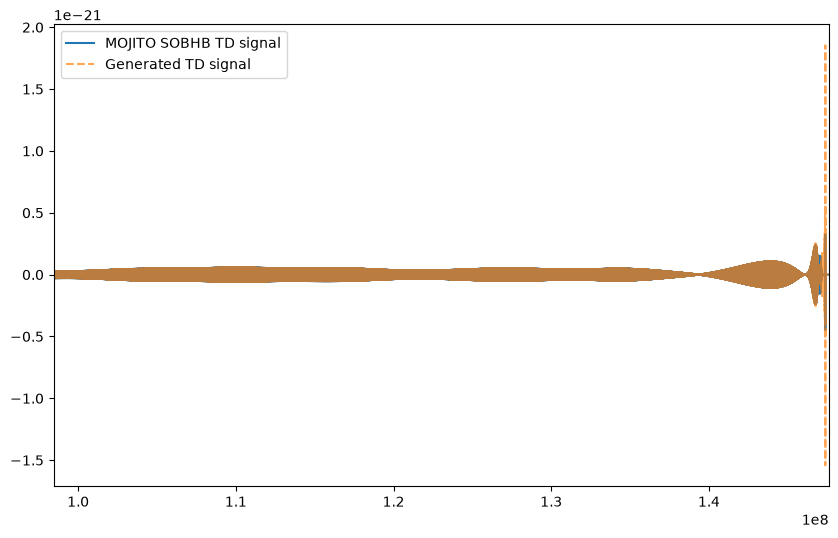

In [63]:
plt.figure(figsize=FIGSIZE)
plt.plot(loader.td_signal.settings.t_arr, loader.td_signal.arr[0], label="MOJITO SOBHB TD signal")
plt.plot(signal.settings.t_arr, signal.arr[0], ls = "--", label="Generated TD signal", alpha = 0.7)
plt.legend(loc="upper left")

plt.xlim(loader.td_signal.settings.t_arr[0], 1.476e8)

plt.show()

In [69]:
t_cut = 1.476e8
new_N = int((t_cut - loader.td_signal.settings.t_arr[0]) / loader.td_signal.settings.dt)
new_td_settings = TDSettings(dt=loader.td_signal.settings.dt, N=new_N, t0=loader.td_signal.settings.t0, force_backend="cpu")

In [72]:
new_signal = TDSignal(arr=signal.arr[:, :new_N], settings=new_td_settings)
new_data = TDSignal(arr=loader.td_signal.arr[:, :new_N], settings=new_td_settings)

In [73]:
fd_settings_factory = FDSettings.make_factory(FREQ_MIN, FREQ_MAX)
fd_settings = fd_settings_factory(new_td_settings.t_arr, new_td_settings.dt, force_backend="cpu")

In [74]:
window_fd = tukey(new_N, alpha=0.1)
signal_fd = new_signal.transform(fd_settings, window_fd)
data_fd = new_data.transform(fd_settings, window_fd)

In [79]:
sensitivity_backend = XYZSensitivityBackend(
        orbits=orbits,
        settings=fd_settings,
        force_backend="cpu",
        tdi_generation=2,
        mask_percentage=0.05,
        window_values=window_fd,
        average_transfer_functions=False,
    )

Soms = 15e-12
Sa =  3e-15

sensitivity_backend.set_sensitivity_matrix(Soms, Sa)

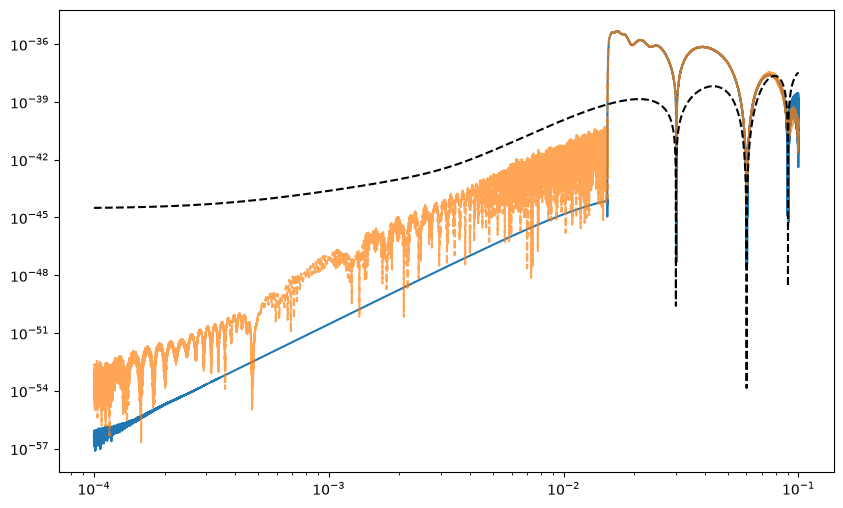

In [84]:
plt.figure(figsize=FIGSIZE)
plt.plot(fd_settings.f_arr, np.abs(asnumpy(data_fd.arr[0])) ** 2, label="MOJITO SOBHB FD signal")
plt.plot(fd_settings.f_arr, np.abs(asnumpy(signal_fd.arr[0])) ** 2, label="Generated FD signal", alpha = 0.7, ls="--")

plt.plot(fd_settings.f_arr, np.abs(sensitivity_backend.sens_mat[0, 0]), label="Sensitivity", c="k", ls="--")
plt.xscale("log")
plt.yscale("log")
plt.show()

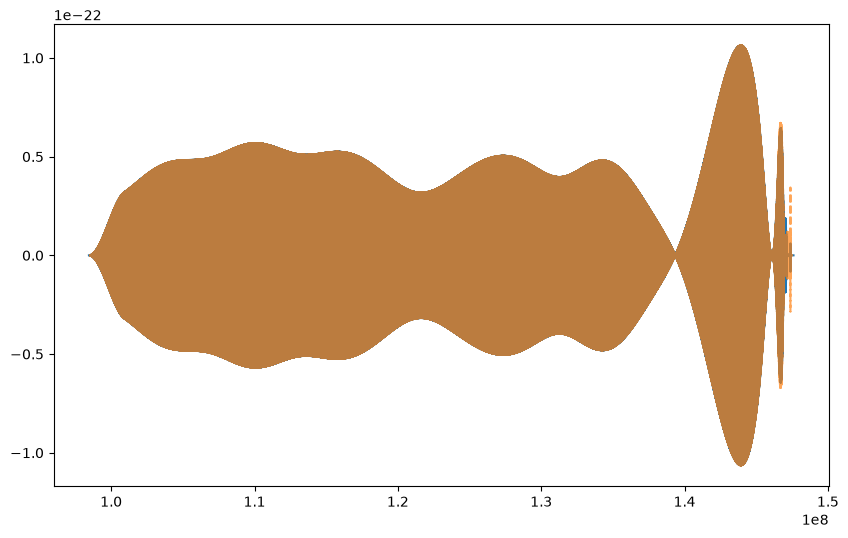

In [86]:
plt.figure(figsize=FIGSIZE)
plt.plot(new_td_settings.t_arr, new_data.arr[0] * window_fd, label="MOJITO SOBHB TD signal")
plt.plot(new_td_settings.t_arr, new_signal.arr[0] * window_fd, label="Generated TD signal", alpha = 0.7, ls="--")